# Lab 2: PID Controller for Robot Navigation

This notebook contains code to load and visualize robot trajectory data from the runs directory.

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import json
import os

## Reference Trajectory

In [8]:
# Reference curves from planner.py: (label, y(x), x_max), sampled into 30 waypoints like the planner.
# The sigmoid was changed mid-lab (commit 0d5d44e): the first sigmoid run used the lab-spec curve,
# later runs used the stretched one. params.json doesn't record which, so keep both and pick the closer.
REFERENCE_CURVES = {
    "parabola": [
        ("y = x^2", lambda x: x**2, 1.5),
    ],
    "sigmoid": [
        ("y = 2/(1+e^(-2x)) - 1", lambda x: 2 / (1 + np.exp(-2 * x)) - 1, 2.5),
        ("y = 2/(1+e^(-x)) - 1", lambda x: 2 / (1 + np.exp(-x)) - 1, 4.0),
    ],
}

def reference_path(run_path, x_robot, y_robot, num_points=30):
    """Return (ref_x, ref_y, label) for the path the planner commanded in this run."""
    with open(os.path.join(run_path, "params.json")) as f:
        params = json.load(f)

    # Point runs have no path, only a goal
    if params["motion"] == "point":
        gx, gy = params["goal"]
        return np.array([gx]), np.array([gy]), f"goal ({gx}, {gy})"

    best = None
    for label, curve, x_max in REFERENCE_CURVES[params["trajectory"]]:
        ref_x = np.linspace(0.0, x_max, num_points)
        ref_y = curve(ref_x)
        # Mean distance from each robot pose to its nearest reference waypoint
        dist = np.hypot(x_robot[:, None] - ref_x, y_robot[:, None] - ref_y).min(axis=1).mean()
        if best is None or dist < best[0]:
            best = (dist, ref_x, ref_y, f"{label}, x in [0, {x_max}]")
    return best[1:]

## Runs

In [9]:
# Runs to plot, keyed by controller (paths are relative to this notebook's folder, lab2/).
# Both follow the parabola with the same P gains (klp=0.2, kap=1.0). The P run used a tighter
# final-goal tolerance (0.01 vs 0.05 m), so it runs a little longer at the end of the path.
RUN_PATHS = {
    "PID": "runs/trajectory_parabola_PID_20261028-180353/",
    "P": "runs/trajectory_parabola_P_20261028-173605/",
}

def load_run(run_path):
    """Load a run's robot_pose.csv and the reference path the planner commanded for it."""
    # CSV headers are "x, y, theta, stamp, " -> strip the spaces and drop the empty trailing column
    df = pd.read_csv(os.path.join(run_path, "robot_pose.csv"), skipinitialspace=True)
    df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
    x, y = df['x'].values, df['y'].values
    ref_x, ref_y, ref_label = reference_path(run_path, x, y)
    return {'path': run_path, 'x': x, 'y': y, 'theta': df['theta'].values, 'stamp': df['stamp'].values,
            'ref_x': ref_x, 'ref_y': ref_y, 'ref_label': ref_label}

runs = {name: load_run(path) for name, path in RUN_PATHS.items()}
for name, run in runs.items():
    print(f"{name}: {os.path.basename(os.path.normpath(run['path']))} -> reference {run['ref_label']}")

PID: trajectory_parabola_PID_20261028-180353 -> reference y = x^2, x in [0, 1.5]
P: trajectory_parabola_P_20261028-173605 -> reference y = x^2, x in [0, 1.5]


## Position Plot

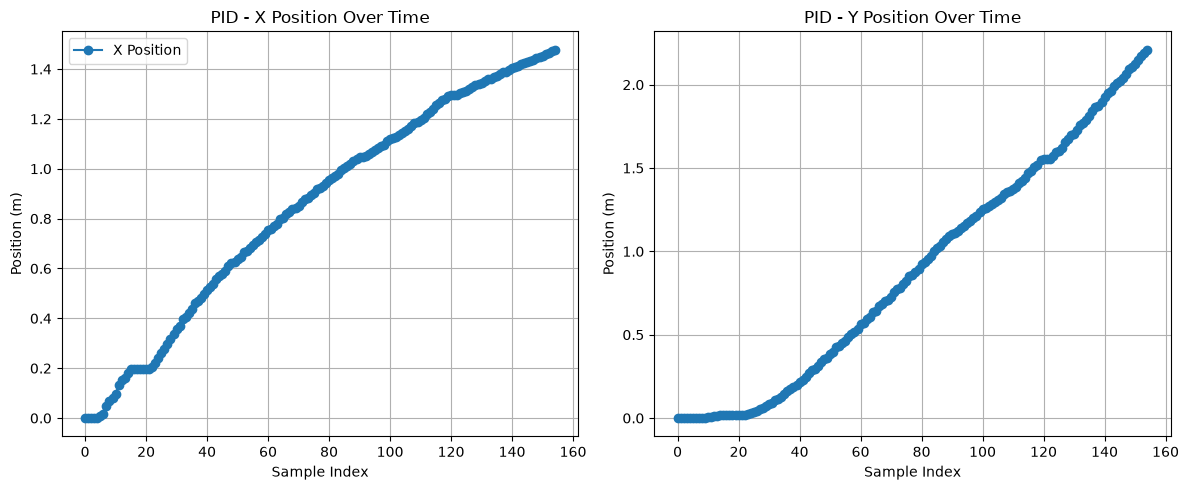

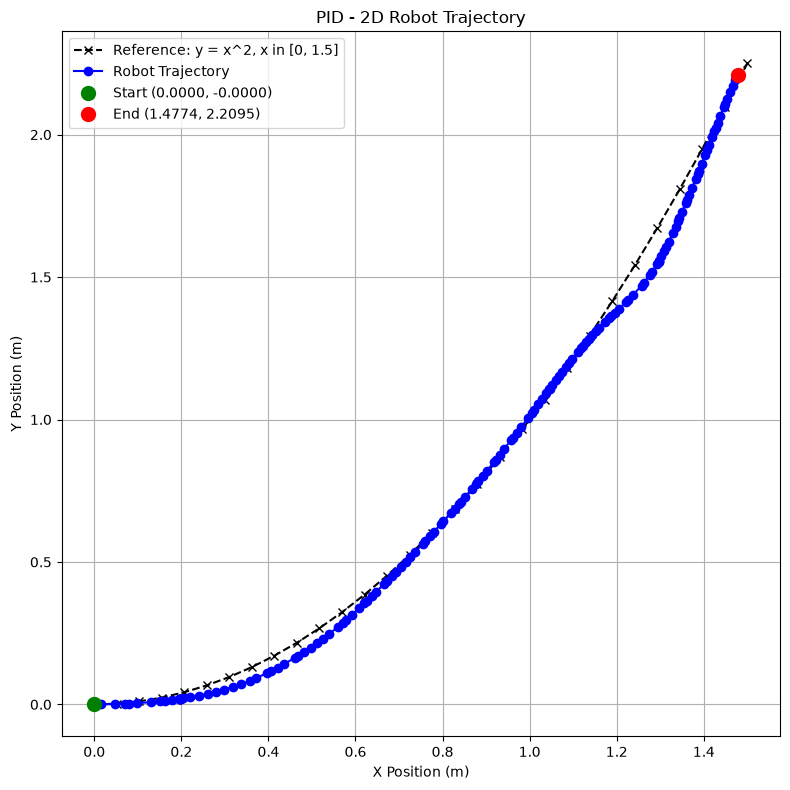

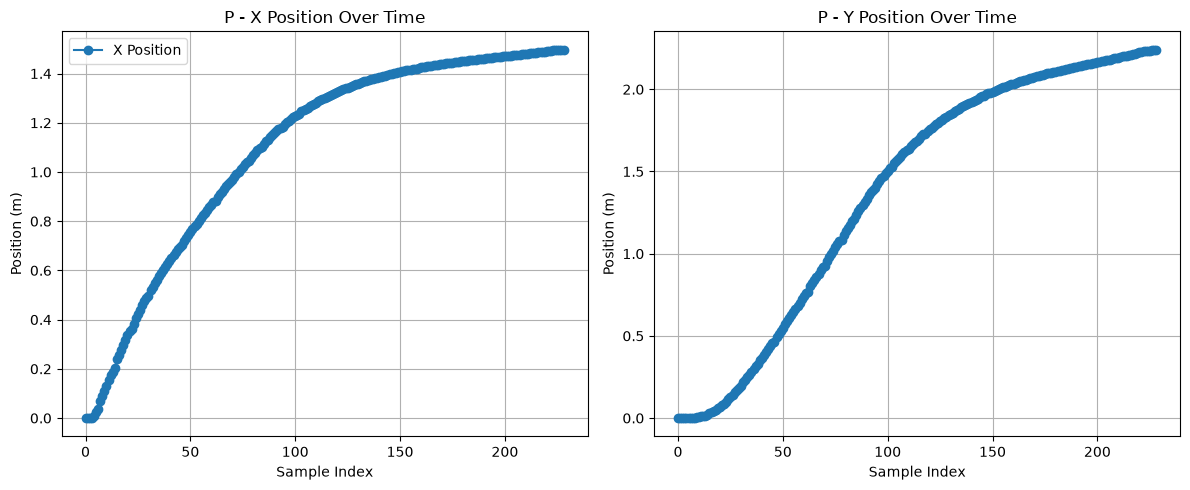

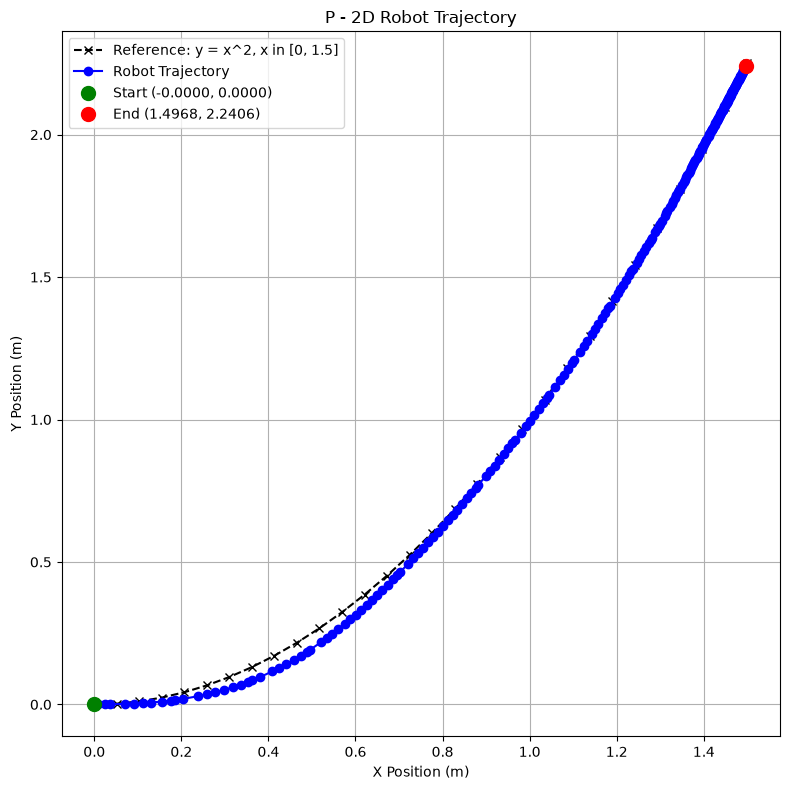

In [10]:
for name, run in runs.items():
    x_positions, y_positions = run['x'], run['y']

    # Create position plot (x vs y)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Plot x and y positions
    ax[0].plot(x_positions, label='X Position', marker='o')
    ax[0].set_xlabel('Sample Index')
    ax[0].set_ylabel('Position (m)')
    ax[0].set_title(f'{name} - X Position Over Time')
    ax[0].grid(True)
    ax[0].legend()

    # Plot y position
    ax[1].plot(y_positions, marker='o')
    ax[1].set_xlabel('Sample Index')
    ax[1].set_ylabel('Position (m)')
    ax[1].set_title(f'{name} - Y Position Over Time')
    ax[1].grid(True)

    plt.tight_layout()
    plt.show()

    # Create 2D trajectory plot
    fig, ax = plt.subplots(1, figsize=(8, 8))

    ax.plot(run['ref_x'], run['ref_y'], 'k--', marker='x', label=f"Reference: {run['ref_label']}")
    ax.plot(x_positions, y_positions, 'b-', marker='o', label='Robot Trajectory')
    ax.set_xlabel('X Position (m)')
    ax.set_ylabel('Y Position (m)')
    ax.set_title(f'{name} - 2D Robot Trajectory')
    ax.grid(True)
    ax.legend()

    # Add start and end markers
    ax.plot(x_positions[0], y_positions[0], 'go', markersize=10, label=f'Start ({x_positions[0]:.4f}, {y_positions[0]:.4f})')
    ax.plot(x_positions[-1], y_positions[-1], 'ro', markersize=10, label=f'End ({x_positions[-1]:.4f}, {y_positions[-1]:.4f})')
    ax.legend()

    plt.tight_layout()
    plt.show()

## Heading Plot

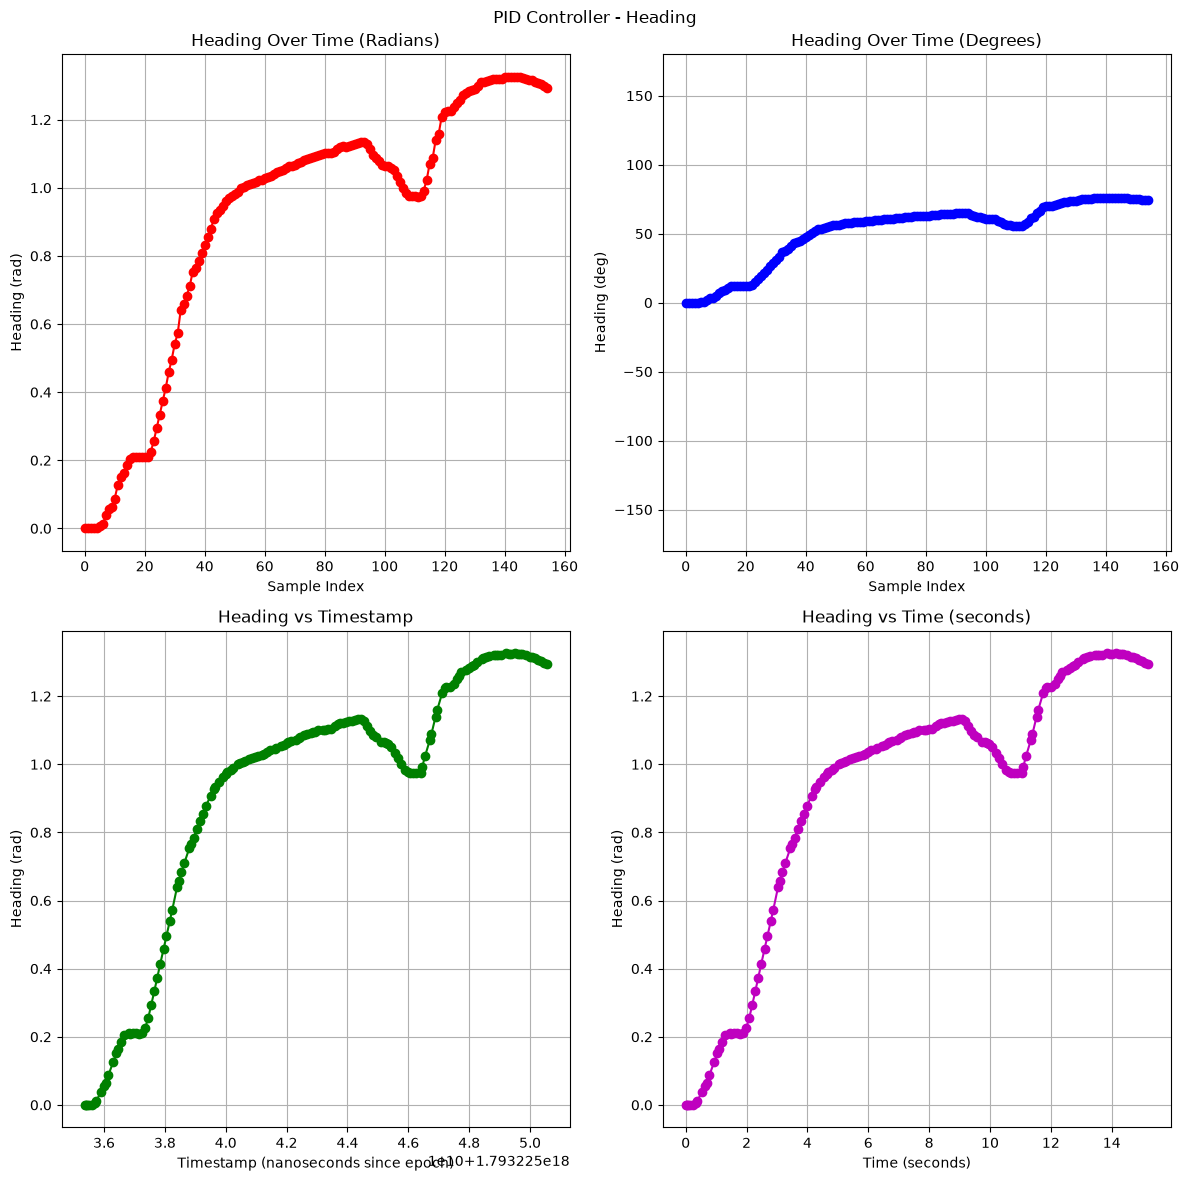

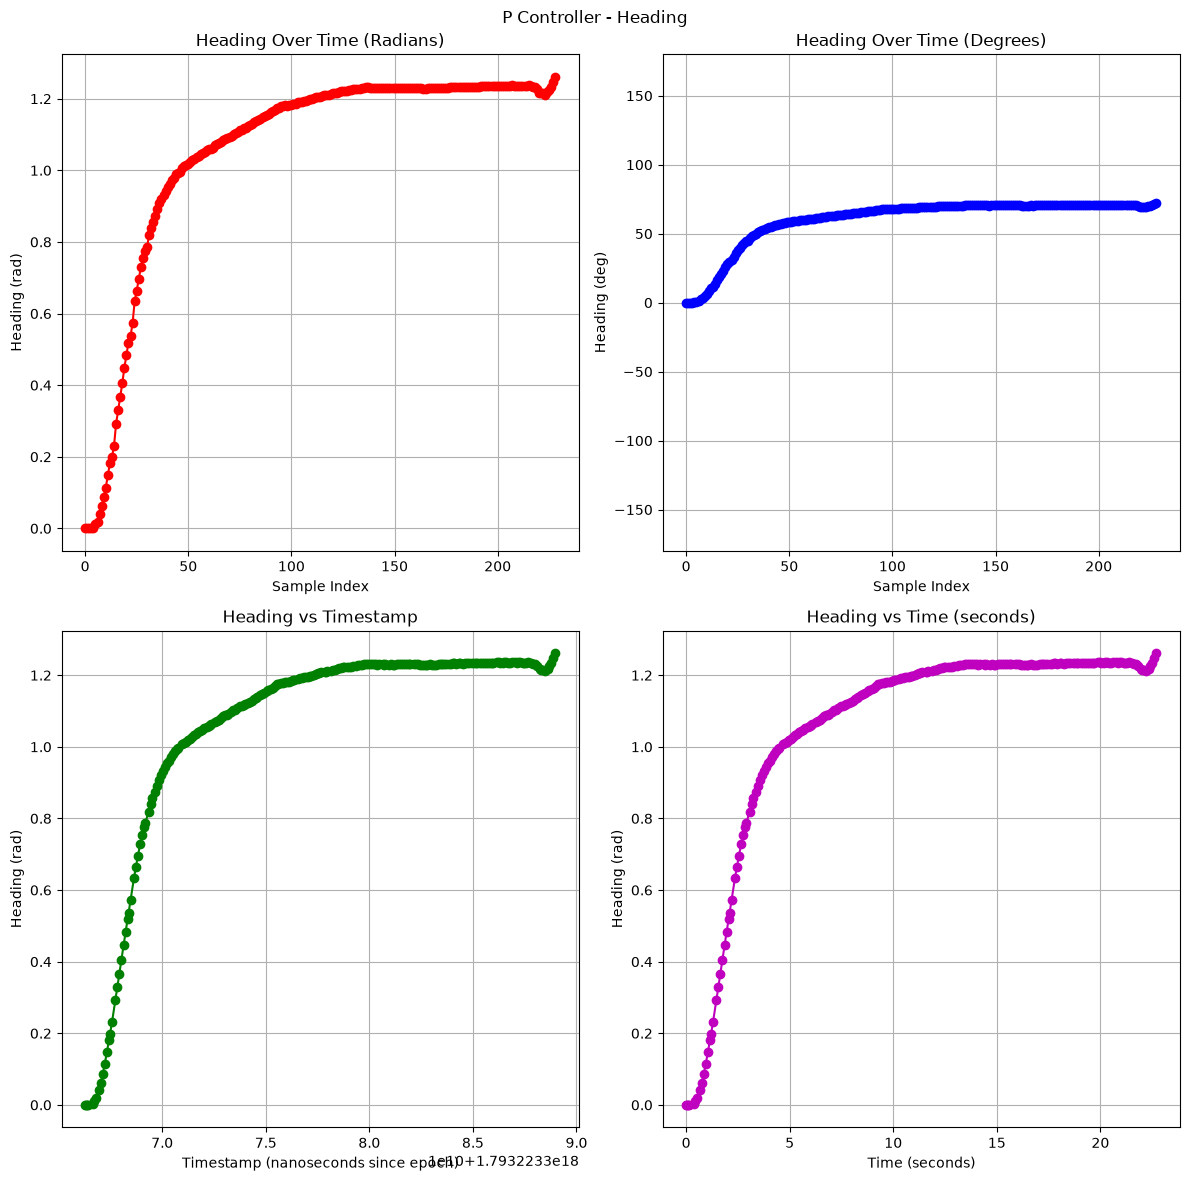

In [11]:
for name, run in runs.items():
    # Extract heading (theta) data
    theta = run['theta']

    # Create heading plot
    fig, axs = plt.subplots(2, 2, figsize=(12, 12))
    fig.suptitle(f'{name} Controller - Heading')

    # Plot theta in radians (raw)
    axs[0, 0].plot(theta, 'r-', marker='o')
    axs[0, 0].set_xlabel('Sample Index')
    axs[0, 0].set_ylabel('Heading (rad)')
    axs[0, 0].set_title('Heading Over Time (Radians)')
    axs[0, 0].grid(True)

    # Convert theta to degrees
    theta_deg = np.degrees(theta)

    # Plot heading in degrees
    axs[0, 1].plot(theta_deg, 'b-', marker='o')
    axs[0, 1].set_xlabel('Sample Index')
    axs[0, 1].set_ylabel('Heading (deg)')
    axs[0, 1].set_title('Heading Over Time (Degrees)')
    axs[0, 1].grid(True)
    axs[0, 1].set_ylim(-180, 180)

    # Plot heading vs time in seconds
    stamp = run['stamp']
    axs[1, 0].plot(stamp, theta, 'g-', marker='o')
    axs[1, 0].set_xlabel('Timestamp (nanoseconds since epoch)')
    axs[1, 0].set_ylabel('Heading (rad)')
    axs[1, 0].set_title('Heading vs Timestamp')
    axs[1, 0].grid(True)

    # Plot heading vs time in seconds (relative to the first sample)
    timestamp_sec = (stamp - stamp[0]) / 1e9
    axs[1, 1].plot(timestamp_sec, theta, 'm-', marker='o')
    axs[1, 1].set_xlabel('Time (seconds)')
    axs[1, 1].set_ylabel('Heading (rad)')
    axs[1, 1].set_title('Heading vs Time (seconds)')
    axs[1, 1].grid(True)

    plt.tight_layout()
    plt.show()

## Combined Position and Heading Plot

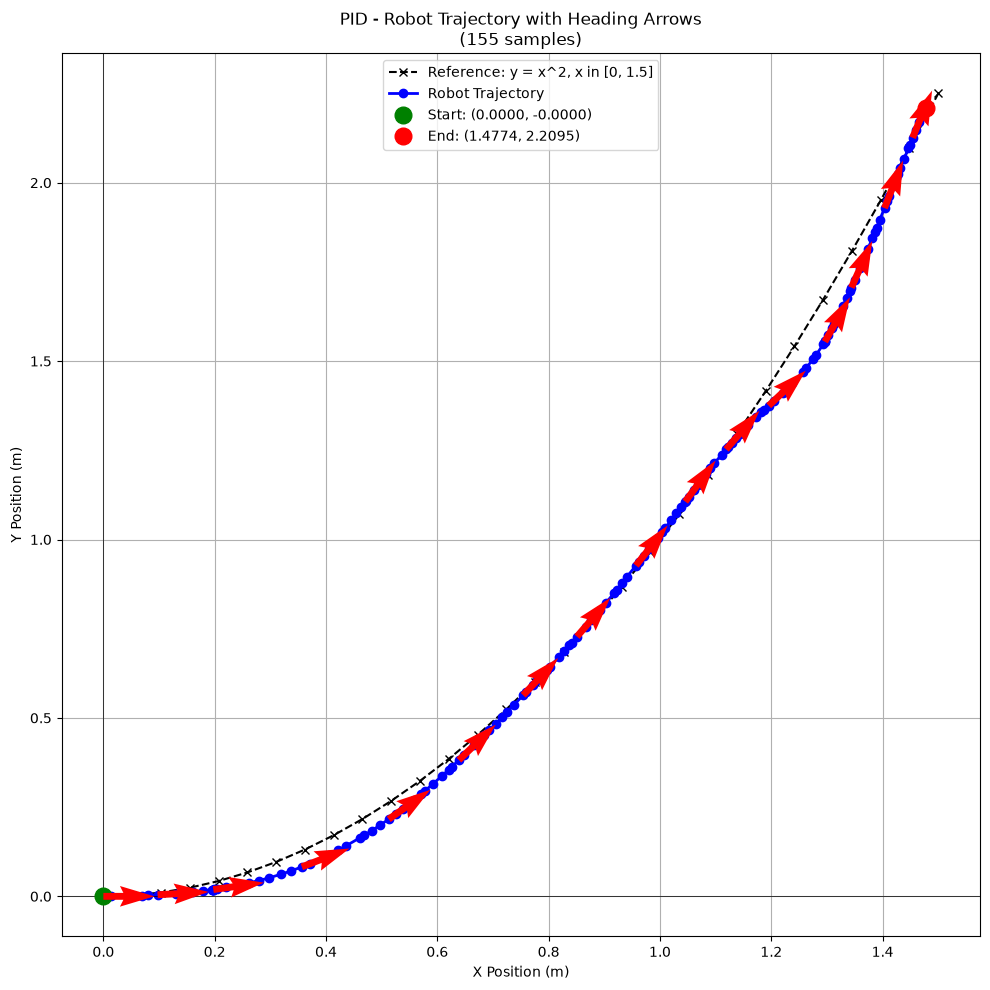

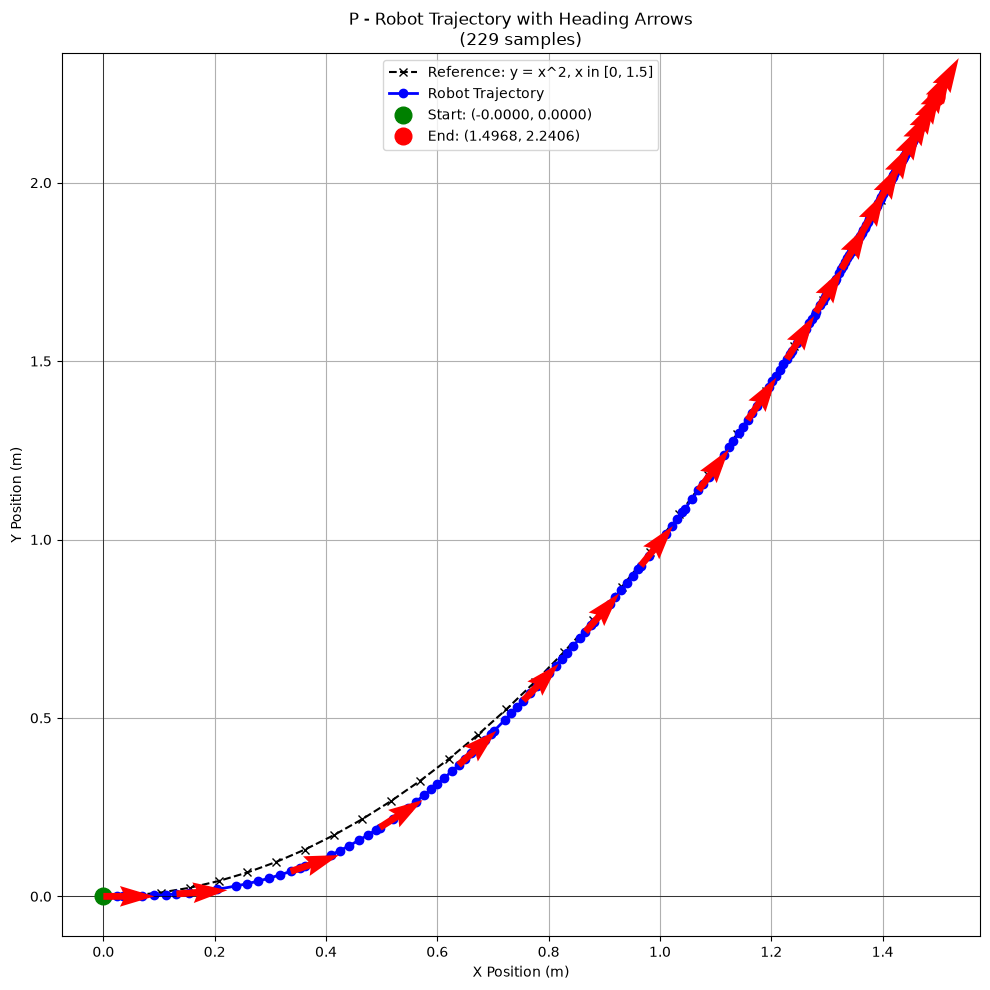

In [12]:
for name, run in runs.items():
    x_positions, y_positions, theta = run['x'], run['y'], run['theta']

    # Create arrow-based trajectory visualization
    fig, ax = plt.subplots(1, figsize=(10, 10))

    # Plot trajectory with arrows showing heading (theta) at every 10th point
    step = 10
    ax.quiver(x_positions[::step], y_positions[::step],
              np.cos(theta[::step]), np.sin(theta[::step]),
              angles='xy', color='r', zorder=3)

    # Draw reference and trajectory lines
    ax.plot(run['ref_x'], run['ref_y'], 'k--', marker='x', label=f"Reference: {run['ref_label']}")
    ax.plot(x_positions, y_positions, 'b-', marker='o', linewidth=2, label='Robot Trajectory')
    ax.set_xlabel('X Position (m)')
    ax.set_ylabel('Y Position (m)')
    ax.set_title(f'{name} - Robot Trajectory with Heading Arrows\n({len(theta)} samples)')
    ax.grid(True)
    ax.axhline(y=0, color='k', linewidth=0.5)
    ax.axvline(x=0, color='k', linewidth=0.5)

    # Add start and end points
    ax.plot(x_positions[0], y_positions[0], 'go', markersize=12,
           label=f'Start: ({x_positions[0]:.4f}, {y_positions[0]:.4f})')
    ax.plot(x_positions[-1], y_positions[-1], 'ro', markersize=12,
           label=f'End: ({x_positions[-1]:.4f}, {y_positions[-1]:.4f})')

    legend = ax.legend()
    legend.get_frame().set_alpha(0.8)

    plt.tight_layout()
    plt.show()

In [13]:
for name, run in runs.items():
    x_positions, y_positions, theta = run['x'], run['y'], run['theta']

    # Load and display run name from directory
    run_dir = os.path.basename(os.path.normpath(run['path']))
    print(f"[{name}] Run Directory: {run_dir}")
    print(f"Number of samples: {len(theta)}")
    print(f"Duration: {(run['stamp'][-1] - run['stamp'][0]) / 1e9:.2f} s")
    print(f"Initial position: x={x_positions[0]:.6f}, y={y_positions[0]:.6f}")
    print(f"Final position: x={x_positions[-1]:.6f}, y={y_positions[-1]:.6f}")
    print(f"Initial heading: {theta[0]:.6f} rad ({np.degrees(theta[0]):.2f}°)")
    print(f"Final heading: {theta[-1]:.6f} rad ({np.degrees(theta[-1]):.2f}°)")
    print()

[PID] Run Directory: trajectory_parabola_PID_20261028-180353
Number of samples: 155
Duration: 15.18 s
Initial position: x=0.000000, y=-0.000000
Final position: x=1.477433, y=2.209528
Initial heading: 0.000000 rad (0.00°)
Final heading: 1.293366 rad (74.10°)

[P] Run Directory: trajectory_parabola_P_20261028-173605
Number of samples: 229
Duration: 22.71 s
Initial position: x=-0.000000, y=0.000000
Final position: x=1.496803, y=2.240554
Initial heading: -0.000002 rad (-0.00°)
Final heading: 1.260928 rad (72.25°)

